# Southern California OSM 2D building view-factor graph

This workflow builds the existing 2D OpenView graph for buildings within one mile of the Southern California **WUI Interface**. The downloaded California GeoParquet contains `WUI_DESC`, so Interface can be separated from Intermix, Influence Zone, and Not WUI. OSM footprints provide geometry; height and terrain are intentionally excluded.

The large Geofabrik download and full graph run are both explicit opt-ins. All graph stages are resumable.

In [1]:
from pathlib import Path
import os
import json

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyogrio
import shapely

from openviewcore.network import (
    BVFGraphConfig, SoCal2DSourceConfig, SoCal2DSourceResult,
    build_bvf_graph, download_geofabrik_socal, extract_geopackage_archive,
    prepare_socal_2d_source,
)

In [2]:
# Resolve the repository whether Jupyter starts at the repo root or notebooks/eda.
PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
RAW = PROJECT / 'data' / 'external' / 'socal'
PREPARED = PROJECT / 'data' / 'processed' / 'socal_wui_osm_2d'
RUNS = PROJECT / 'results' / 'socal_wui_osm_2d'
for path in (RAW, PREPARED, RUNS):
    path.mkdir(parents=True, exist_ok=True)

TARGET_CRS = 'EPSG:3310'  # California Albers, metres
DOWNLOAD_OSM = False      # ~1.1 GB compressed; set True once on the large machine
REBUILD_SOURCE = False
RUN_FULL_SOCAL = False
WORKERS = max(1, (os.cpu_count() or 2) - 1)

## 1. Cache source data

The WUI input is the manually downloaded California GeoParquet. For OSM, use the free Geofabrik Southern California GeoPackage: it can be spatially filtered directly and does not require parsing the full PBF in Python.

In [3]:
WUI = Path('/Users/adamswietek/Documents/PostDoc/data/raw_la/fire/20260728T155639Z_b866/part-00000.parquet')
if not WUI.exists():
    raise FileNotFoundError(WUI)

OSM_ZIP = RAW / 'socal-latest-free.gpkg.zip'
osm_candidates = [
    RAW / 'socal.gpkg',
    *sorted(RAW.glob('*-free.gpkg')),
    *sorted(RAW.glob('*latest*.gpkg')),
]
OSM_GPKG = next((path for path in osm_candidates if path.exists()), None)
if OSM_GPKG is None and DOWNLOAD_OSM:
    download_geofabrik_socal(OSM_ZIP)
    OSM_GPKG = extract_geopackage_archive(OSM_ZIP, RAW)
if OSM_GPKG is None:
    raise FileNotFoundError(
        f'Place the extracted Geofabrik socal GeoPackage in {RAW}, '
        'or set DOWNLOAD_OSM=True.'
    )
OSM_GPKG

PosixPath('/Users/adamswietek/Documents/PostDoc/openview/data/external/socal/socal.gpkg')

## 2. Prepare one-mile nodes plus blocker halo

The analysis mask is WUI + 1 mile. The source mask adds the graph's maximum link distance so a building just outside the analysis boundary can still block a ray. Footprints are normalized once to a spatially indexed FlatGeobuf with compact integer IDs.

In [5]:
source_cfg = SoCal2DSourceConfig(
    target_crs=TARGET_CRS, wui_buffer_m=1609.344,
    blocker_halo_m=152.45, wui_simplify_m=25.0,
    wui_class_column='WUI_DESC', wui_classes=('Interface',),
)
expected = {
    'wui_path': PREPARED / 'socal_wui.gpkg',
    'analysis_mask_path': PREPARED / 'socal_wui_analysis_mask.gpkg',
    'source_mask_path': PREPARED / 'socal_wui_source_mask.gpkg',
    'buildings_path': PREPARED / 'socal_wui_osm_buildings.fgb',
    'manifest_path': PREPARED / 'source_manifest.json',
}
can_reuse = all(path.exists() for path in expected.values())
if can_reuse:
    old_manifest = json.loads(expected['manifest_path'].read_text())
    can_reuse = (
        old_manifest.get('wui_input') == str(WUI.resolve())
        and old_manifest.get('wui_classes') == ['Interface']
    )
if REBUILD_SOURCE or not can_reuse:
    source_result = prepare_socal_2d_source(OSM_GPKG, WUI, PREPARED, config=source_cfg)
else:
    source_result = SoCal2DSourceResult(output_dir=PREPARED, **expected)
analysis_mask = gpd.read_file(source_result.analysis_mask_path, layer='mask')
source_result

SoCal2DSourceResult(output_dir=PosixPath('/Users/adamswietek/Documents/PostDoc/openview/data/processed/socal_wui_osm_2d'), wui_path=PosixPath('/Users/adamswietek/Documents/PostDoc/openview/data/processed/socal_wui_osm_2d/socal_wui.gpkg'), analysis_mask_path=PosixPath('/Users/adamswietek/Documents/PostDoc/openview/data/processed/socal_wui_osm_2d/socal_wui_analysis_mask.gpkg'), source_mask_path=PosixPath('/Users/adamswietek/Documents/PostDoc/openview/data/processed/socal_wui_osm_2d/socal_wui_source_mask.gpkg'), buildings_path=PosixPath('/Users/adamswietek/Documents/PostDoc/openview/data/processed/socal_wui_osm_2d/socal_wui_osm_buildings.fgb'), manifest_path=PosixPath('/Users/adamswietek/Documents/PostDoc/openview/data/processed/socal_wui_osm_2d/source_manifest.json'))

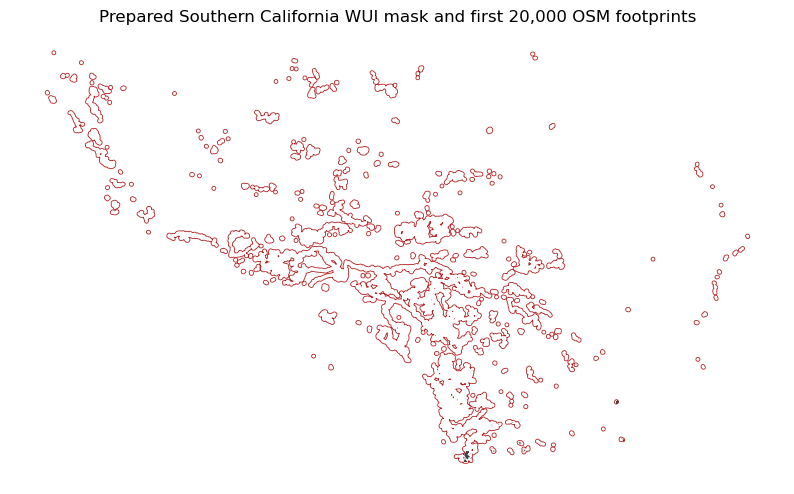

In [6]:
# Quick footprint/mask QA without reading the regional building file in full.
preview = pyogrio.read_dataframe(source_result.buildings_path, max_features=20_000)
ax = analysis_mask.boundary.plot(figsize=(10, 10), color='firebrick', linewidth=0.6)
preview.plot(ax=ax, color='0.25', linewidth=0, alpha=0.6)
ax.set_title('Prepared Southern California WUI mask and first 20,000 OSM footprints')
ax.set_axis_off();

## 3. Two-tile smoke test

The test chooses the tile containing the first prepared footprint plus its eastern neighbor. The same WUI mask selects graph nodes; halo footprints remain blockers. The `bvh` backend is the fast 2D footprint-curtain ray path already implemented in OpenView.

In [7]:
TILE_M = 2_000.0
first = pyogrio.read_dataframe(source_result.buildings_path, max_features=1).geometry.iloc[0].centroid
ix, iy = int(first.x // TILE_M), int(first.y // TILE_M)
test_bounds = (ix*TILE_M, iy*TILE_M, (ix+2)*TILE_M, (iy+1)*TILE_M)
graph_cfg = BVFGraphConfig(
    id_column='building_id', source_id_column='source_building_id',
    target_crs=TARGET_CRS, tile_size_m=TILE_M,
    max_distance_m=152.4, max_angle_deg=80.0,
    visibility_backend='bvh', workers=1, resume=True,
)
test_result = build_bvf_graph(
    source_result.buildings_path, RUNS / 'two_tile_test', config=graph_cfg,
    bounds=test_bounds, max_tiles=2, selection_mask=analysis_mask,
)
pd.read_parquet(test_result.building_metrics_path).describe()

2D BVF tiles:   0%|          | 0/1 [00:00<?, ?tile/s]

setting thread affinity failed


tile 208_-276: 3,687 facade patches:   0%|          | 0/8 [00:00<?, ?batch/s]

,building_id,perimeter_m,exchange_total_m,neighbor_count,bvf_all_edges,bvf_noncontact_edges,bvf_contact_edges,bvf_max
count,3.470000e+02,347.000000,347.000000,347.000000,347.000000,347.000000,347.000000,347.000000
mean,7.076054e+05,71.000883,46.863152,17.262248,0.680422,0.678574,0.001848,0.745523
std,2.197936e+05,43.826262,23.002618,7.122206,0.167197,0.170383,0.034427,0.219138
min,4.701720e+05,5.765600,3.910749,2.000000,0.122689,0.068703,0.000000,0.161788
25%,6.947955e+05,49.663359,28.334517,12.000000,0.572387,0.572207,0.000000,0.584183
50%,6.948860e+05,70.333251,47.175365,17.000000,0.705623,0.704499,0.000000,0.798646
75%,6.953155e+05,85.026888,62.864254,22.000000,0.815761,0.815761,0.000000,0.940214
max,3.016151e+06,608.215497,126.121723,40.000000,1.000000,1.000000,0.641308,1.000000


## 4. Full Southern California run

Set `RUN_FULL_SOCAL=True`. Tile partitions and completion markers make the run resumable after interruption. Start with physical cores rather than every logical CPU, and watch memory before increasing workers because each worker loads its own tile plus 500-foot halo.

In [ ]:
FULL_RUN = RUNS / 'full_socal'
# RUN_FULL_SOCAL = True
if RUN_FULL_SOCAL:
    full_cfg = BVFGraphConfig(
        id_column='building_id', source_id_column='source_building_id',
        target_crs=TARGET_CRS, tile_size_m=TILE_M,
        max_distance_m=152.4, max_angle_deg=80.0,
        visibility_backend='bvh', workers=WORKERS, resume=True,
    )
    full_result = build_bvf_graph(
        source_result.buildings_path, FULL_RUN, config=full_cfg,
        selection_mask=analysis_mask,
    )
    print(full_result.manifest_path)
else:
    print('Full run disabled; set RUN_FULL_SOCAL=True after the two-tile test passes.')

2D BVF tiles:   0%|          | 0/7536 [00:00<?, ?tile/s]

setting thread affinity failed
setting thread affinity failed
setting thread affinity failed
setting thread affinity failed
setting thread affinity failed
setting thread affinity failed
setting thread affinity failed

setting thread affinity failed
setting thread affinity failedWarning: setting thread affinity failed

setting thread affinity failed
setting thread affinity failed

setting thread affinity failed

setting thread affinity failed

setting thread affinity failedWarning: Warning: setting thread affinity failed
setting thread affinity failed

setting thread affinity failedWarning: 
setting thread affinity failed
setting thread affinity failed
setting thread affinity failed

setting thread affinity failed
setting thread affinity failed
setting thread affinity failed
setting thread affinity failed
setting thread affinity failed







setting thread affinity failed
setting thread affinity failed
setting thread affinity failed
setting thread affinity failed

setting thread affini

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

/Users/adamswietek/Documents/PostDoc/openview/results/socal_wui_osm_2d/full_socal/manifest.json


## 5. Load either completed run and map a building metric

This cell uses files on disk, so it also works after restarting the kernel. Set `ACTIVE_RUN` to the full or test directory.

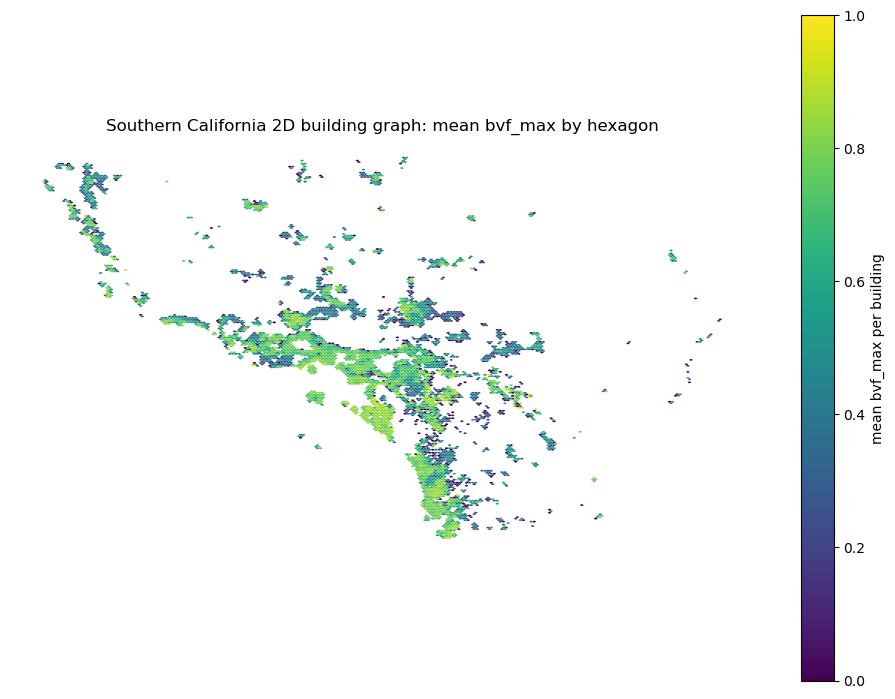

In [4]:
# Standalone result loader: safe after a kernel restart.
from pathlib import Path
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyogrio
import shapely

PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
PREPARED = PROJECT / 'data' / 'processed' / 'socal_wui_osm_2d'
RUNS = PROJECT / 'results' / 'socal_wui_osm_2d'
BUILDINGS_PATH = PREPARED / 'socal_wui_osm_buildings.fgb'
ANALYSIS_MASK_PATH = PREPARED / 'socal_wui_analysis_mask.gpkg'
FULL_RUN = RUNS / 'full_socal'
TEST_RUN = RUNS / 'two_tile_test'
ACTIVE_RUN = FULL_RUN if (FULL_RUN / 'manifest.json').exists() else TEST_RUN
required = [BUILDINGS_PATH, ANALYSIS_MASK_PATH, ACTIVE_RUN / 'building_metrics.parquet']
missing = [path for path in required if not path.exists()]
if missing:
    raise FileNotFoundError(f'Missing completed workflow outputs: {missing}')

analysis_mask = gpd.read_file(ANALYSIS_MASK_PATH, layer='mask')
RESULT_HALO_M = 152.4
reporting_geometry = shapely.buffer(
    analysis_mask.geometry.union_all(), -RESULT_HALO_M,
)
metrics = pd.read_parquet(ACTIVE_RUN / 'building_metrics.parquet')
nodes = pyogrio.read_dataframe(
    BUILDINGS_PATH, columns=['building_id'],
    mask=reporting_geometry,
)
node_points = shapely.point_on_surface(nodes.geometry.to_numpy())
nodes = nodes[shapely.within(node_points, reporting_geometry)].copy()
nodes = nodes.merge(metrics, on='building_id', how='inner', validate='one_to_one')

# Hexbin is much faster and clearer than drawing millions of individual points.
metric = 'bvf_max'  # also: bvf_all_edges, bvf_noncontact_edges, bvf_max
HEX_GRID_SIZE = 220
HEX_STATISTIC = 'mean'       # mean, median, or sum
reducers = {'mean': np.nanmean, 'median': np.nanmedian, 'sum': np.nansum}
centroids = nodes.geometry.centroid
x = centroids.x.to_numpy()
y = centroids.y.to_numpy()
values = nodes[metric].to_numpy(dtype=float)
valid = np.isfinite(x) & np.isfinite(y) & np.isfinite(values)

fig, ax = plt.subplots(figsize=(12, 12))
hexes = ax.hexbin(
    x[valid], y[valid], C=values[valid], gridsize=HEX_GRID_SIZE,
    reduce_C_function=reducers[HEX_STATISTIC], mincnt=1,
    cmap='viridis', linewidths=0,
)
colorbar = fig.colorbar(hexes, ax=ax, shrink=0.72)
colorbar.set_label(f'{HEX_STATISTIC} {metric} per building')
ax.set_title(f'Southern California 2D building graph: {HEX_STATISTIC} {metric} by hexagon')
ax.set_aspect('equal')
ax.set_axis_off();

In [3]:
# Interactive accuracy viewer for a small section (standalone cell).
from pathlib import Path
import json
import duckdb
import geopandas as gpd
import ipywidgets as widgets
import numpy as np
import pandas as pd
import pyogrio
import shapely
from IPython.display import display
from ipyleaflet import GeoJSON, LayerGroup, Map, basemaps
from shapely.geometry import Point

# Change these to inspect another location. Coordinates are (longitude, latitude).
SECTION_CENTER_LON_LAT = (-118.2702, 34.0869)  # Silver Lake
SECTION_RADIUS_M = 750.0
MAX_LINK_DISTANCE_M = 152.4
MAX_MAP_EDGES = 150
VISIBLE_LINKS_ONLY = True
EDGE_SCORE = 'vf'  # 'vf' for whole-building directional VF; 'f_max' for strongest patch coupling

PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
PREPARED = PROJECT / 'data' / 'processed' / 'socal_wui_osm_2d'
ACTIVE_RUN = PROJECT / 'results' / 'socal_wui_osm_2d' / 'full_socal'
BUILDINGS_PATH = PREPARED / 'socal_wui_osm_buildings.fgb'
METRICS_PATH = ACTIVE_RUN / 'building_metrics.parquet'
EDGES_PATH = ACTIVE_RUN / 'building_edges.parquet'

center = gpd.GeoSeries([Point(SECTION_CENTER_LON_LAT)], crs=4326).to_crs(3310).iloc[0]
section_mask = center.buffer(SECTION_RADIUS_M)
display_mask = center.buffer(SECTION_RADIUS_M + MAX_LINK_DISTANCE_M + 25.0)
analysis_geometry = gpd.read_file(
    PREPARED / 'socal_wui_analysis_mask.gpkg', layer='mask',
).geometry.union_all()
reporting_geometry = shapely.buffer(analysis_geometry, -MAX_LINK_DISTANCE_M)
core_mask = shapely.intersection(section_mask, reporting_geometry)
footprints = pyogrio.read_dataframe(
    BUILDINGS_PATH, columns=['building_id'], mask=display_mask,
)
footprints['in_core'] = shapely.within(
    shapely.point_on_surface(footprints.geometry.to_numpy()), core_mask,
)
core_ids = footprints.loc[footprints['in_core'], ['building_id']].drop_duplicates()
if core_ids.empty:
    raise ValueError('No graph buildings found here; move SECTION_CENTER_LON_LAT or enlarge the radius.')
if len(core_ids) > 7_500:
    raise ValueError(f'{len(core_ids):,} buildings is too many for a responsive map; reduce SECTION_RADIUS_M.')

# Scan the regional Parquet files once, retaining only this local section.
con = duckdb.connect()
con.register('display_ids', footprints[['building_id']].drop_duplicates())
con.register('core_ids', core_ids)
metrics_sql_path = str(METRICS_PATH).replace("'", "''")
edges_sql_path = str(EDGES_PATH).replace("'", "''")
local_metrics = con.execute(f"""
    SELECT m.* FROM read_parquet('{metrics_sql_path}') m
    SEMI JOIN display_ids d USING (building_id)
""").df()
local_edges = con.execute(f"""
    SELECT e.* FROM read_parquet('{edges_sql_path}') e
    WHERE e.building_i IN (SELECT building_id FROM core_ids)
       OR e.building_j IN (SELECT building_id FROM core_ids)
""").df()
con.close()
if VISIBLE_LINKS_ONLY:
    local_edges = local_edges[local_edges['exchange_visible_ij_m'] > 0].copy()

network_buildings = footprints.merge(
    local_metrics, on='building_id', how='inner', validate='one_to_one',
)
core_buildings = network_buildings[network_buildings['in_core']].copy()
core_wgs84 = core_buildings[[
    'building_id', 'bvf_all_edges', 'bvf_noncontact_edges',
    'bvf_contact_edges', 'bvf_max', 'exchange_total_m',
    'neighbor_count', 'geometry',
]].to_crs(4326)
node_points = footprints[['building_id', 'geometry']].copy()
node_points.geometry = node_points.geometry.representative_point()
node_xy = {int(row.building_id): (row.geometry.x, row.geometry.y) for row in node_points.itertuples()}
print(f'Interactive section: {len(core_buildings):,} buildings; {len(local_edges):,} visible incident edges')

VIRIDIS_STOPS = ['#440154', '#414487', '#2a788e', '#22a884', '#7ad151', '#fde725']
def _number(value, default=np.nan):
    try:
        value = float(value)
    except (TypeError, ValueError):
        return default
    return value if np.isfinite(value) else default

def _color(value):
    value = float(np.clip(value, 0, 1))
    position = value * (len(VIRIDIS_STOPS) - 1)
    left = min(int(position), len(VIRIDIS_STOPS) - 2)
    fraction = position - left
    rgb = []
    for channel in range(3):
        a = int(VIRIDIS_STOPS[left][1 + 2*channel:3 + 2*channel], 16)
        b = int(VIRIDIS_STOPS[left + 1][1 + 2*channel:3 + 2*channel], 16)
        rgb.append(round(a + fraction * (b - a)))
    return '#' + ''.join(f'{channel:02x}' for channel in rgb)

def _building_style(feature):
    value = _number(feature['properties'].get('bvf_all_edges'))
    return {
        'fillColor': _color(value) if np.isfinite(value) else '#d9d9d9',
        'color': '#555555', 'weight': 0.6, 'fillOpacity': 0.78,
    }

def _edge_style(feature):
    p = feature['properties']
    value = np.clip(_number(p.get('selected_score'), 0), 0, 1)
    return {
        'color': '#e66101' if p.get('has_contact') else '#247ba0',
        'weight': 1 + 7*np.sqrt(value), 'opacity': 0.82,
    }

def incident_edges(selected):
    incident = local_edges[
        (local_edges['building_i'] == selected) | (local_edges['building_j'] == selected)
    ].copy()
    if incident.empty:
        return gpd.GeoDataFrame(incident, geometry=[], crs=footprints.crs)
    selected_is_i = incident['building_i'].to_numpy() == selected
    incident['neighbor_building'] = np.where(
        selected_is_i, incident['building_j'], incident['building_i'],
    )
    incident['selected_vf'] = np.where(
        selected_is_i, incident['vf_i_to_j'], incident['vf_j_to_i'],
    )
    incident['neighbor_vf'] = np.where(
        selected_is_i, incident['vf_j_to_i'], incident['vf_i_to_j'],
    )
    incident['selected_f_max'] = np.where(
        selected_is_i, incident['f_max_i_to_j'], incident['f_max_j_to_i'],
    )
    incident['selected_score'] = incident['selected_vf'] if EDGE_SCORE == 'vf' else incident['selected_f_max']
    incident = incident.nlargest(MAX_MAP_EDGES, 'selected_score')
    known = incident['building_i'].isin(node_xy) & incident['building_j'].isin(node_xy)
    incident = incident[known].copy()
    geometry = [
        shapely.LineString([node_xy[int(i)], node_xy[int(j)]])
        for i, j in zip(incident['building_i'], incident['building_j'])
    ]
    return gpd.GeoDataFrame(incident, geometry=geometry, crs=footprints.crs).to_crs(4326)

building_layer = GeoJSON(
    data=json.loads(core_wgs84.to_json()), style_callback=_building_style,
    hover_style={'weight': 2, 'color': '#ffffff', 'fillOpacity': 0.95},
)
# Diagnostic overlays: red dashed = tile seams; magenta = graph edge; cyan = reporting edge.
xmin, ymin, xmax, ymax = display_mask.bounds
tile_x = np.arange(np.floor(xmin/2000)*2000, xmax + 2000, 2000)
tile_y = np.arange(np.floor(ymin/2000)*2000, ymax + 2000, 2000)
grid_geometry = (
    [shapely.LineString([(x, ymin), (x, ymax)]) for x in tile_x]
    + [shapely.LineString([(xmin, y), (xmax, y)]) for y in tile_y]
)
grid_wgs84 = gpd.GeoDataFrame(geometry=grid_geometry, crs=3310).to_crs(4326)
local_analysis_edge = shapely.intersection(
    shapely.boundary(analysis_geometry), display_mask,
)
analysis_edge_wgs84 = gpd.GeoDataFrame(
    geometry=[local_analysis_edge], crs=3310,
).to_crs(4326)
local_reporting_edge = shapely.intersection(
    shapely.boundary(reporting_geometry), display_mask,
)
reporting_edge_wgs84 = gpd.GeoDataFrame(
    geometry=[local_reporting_edge], crs=3310,
).to_crs(4326)
grid_layer = GeoJSON(
    data=json.loads(grid_wgs84.to_json()),
    style={'color': '#d73027', 'weight': 2, 'dashArray': '6 6', 'opacity': 0.75},
)
analysis_edge_layer = GeoJSON(
    data=json.loads(analysis_edge_wgs84.to_json()),
    style={'color': '#cc00cc', 'weight': 3, 'opacity': 0.85},
)
reporting_edge_layer = GeoJSON(
    data=json.loads(reporting_edge_wgs84.to_json()),
    style={'color': '#00bcd4', 'weight': 3, 'opacity': 0.9},
)
selection_layers = LayerGroup(layers=())
network_map = Map(
    center=(SECTION_CENTER_LON_LAT[1], SECTION_CENTER_LON_LAT[0]), zoom=16,
    basemap=basemaps.OpenStreetMap.Mapnik, scroll_wheel_zoom=True,
    layout=widgets.Layout(height='760px', width='100%'),
)
network_map.add(grid_layer)
network_map.add(analysis_edge_layer)
network_map.add(reporting_edge_layer)
network_map.add(building_layer)
network_map.add(selection_layers)
building_details = widgets.HTML('<b>Click a building footprint.</b>')
edge_details = widgets.HTML('Click a displayed link for both directional scores.')

def _on_edge_click(event=None, feature=None, **kwargs):
    p = (feature or {}).get('properties', kwargs.get('properties', {}))
    if not p:
        return
    i, j = int(p['building_i']), int(p['building_j'])
    edge_details.value = (
        f'<b>Building link {i} ↔ {j}</b><br>'
        f'F({i}→{j}) = {_number(p["vf_i_to_j"]):.5f}; '
        f'F({j}→{i}) = {_number(p["vf_j_to_i"]):.5f}<br>'
        f'Fmax({i}→{j}) = {_number(p["f_max_i_to_j"]):.5f}; '
        f'Fmax({j}→{i}) = {_number(p["f_max_j_to_i"]):.5f}<br>'
        f'Visible reciprocal exchange = {_number(p["exchange_visible_ij_m"]):.3f} m; '
        f'contact = {bool(p["has_contact"])}'
    )

def _on_building_click(event=None, feature=None, **kwargs):
    p = (feature or {}).get('properties', kwargs.get('properties', {}))
    if not p or p.get('building_id') is None:
        return
    selected = int(p['building_id'])
    edges = incident_edges(selected)
    selected_polygon = core_wgs84[core_wgs84['building_id'] == selected][['building_id', 'geometry']]
    layers = [GeoJSON(
        data=json.loads(selected_polygon.to_json()),
        style={'color': '#111111', 'weight': 4, 'fillOpacity': 0},
    )]
    if len(edges):
        edge_layer = GeoJSON(
            data=json.loads(edges.to_json()), style_callback=_edge_style,
            hover_style={'weight': 9, 'opacity': 1},
        )
        edge_layer.on_click(_on_edge_click)
        layers.insert(0, edge_layer)
    selection_layers.layers = tuple(layers)
    metric = local_metrics[local_metrics['building_id'] == selected].iloc[0]
    top_rows = ''.join(
        f'<tr><td>{int(row.neighbor_building)}</td><td>{row.selected_vf:.5f}</td>'
        f'<td>{row.selected_f_max:.5f}</td></tr>' for row in edges.head(8).itertuples()
    ) or "<tr><td colspan='3'>No visible neighbors</td></tr>"
    building_details.value = (
        f'<b>Building {selected}</b> | BVF = {metric.bvf_all_edges:.5f} | '
        f'noncontact BVF = {metric.bvf_noncontact_edges:.5f} | BVFmax = {metric.bvf_max:.5f}<br>'
        f'all graph neighbors = {int(metric.neighbor_count):,}; displayed visible links = {len(edges):,}<br>'
        "<span style='font-size:12px'>Width uses the selected directional score; blue = visible, "
        "orange = visible plus physical contact; red dashed = tile seam; magenta = graph edge; "
        "cyan = reporting edge (outer 152.4 m is halo). "
        "Lines join building representative points; "
        "they summarize facade-patch visibility and are not the literal rays used by the solver.</span>"
        "<table><tr><th>Top neighbor</th><th>F</th><th>Fmax</th></tr>" + top_rows + '</table>'
    )
    edge_details.value = 'Click a displayed link for both directional scores.'

building_layer.on_click(_on_building_click)
default_building = int(core_buildings.nlargest(1, 'bvf_noncontact_edges')['building_id'].iloc[0])
_on_building_click(feature={'properties': {'building_id': default_building}})
interactive_accuracy_viewer = widgets.VBox([network_map, building_details, edge_details])
display(interactive_accuracy_viewer)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Interactive section: 403 buildings; 4,468 visible incident edges


,n,mean,q25,median,q75
sample,,,,,
LARIAC downtown (2 tiles),3088,0.7448,0.6410,0.7645,0.8777
LARIAC LA WUI,1027018,0.7593,0.6930,0.7951,0.8646
OSM SoCal WUI,2902123,0.7278,0.6520,0.7753,0.8505
OSM Silver Lake,3478,0.8010,0.7427,0.8156,0.8730
LARIAC Silver Lake,3529,0.8036,0.7479,0.8177,0.8740


,building_count,footprint_area_ha,facade_length_km,median_nearest_building_m
OSM Silver Lake,3480,46.67,171.39,12.72
LARIAC Silver Lake,3538,47.29,173.83,12.58


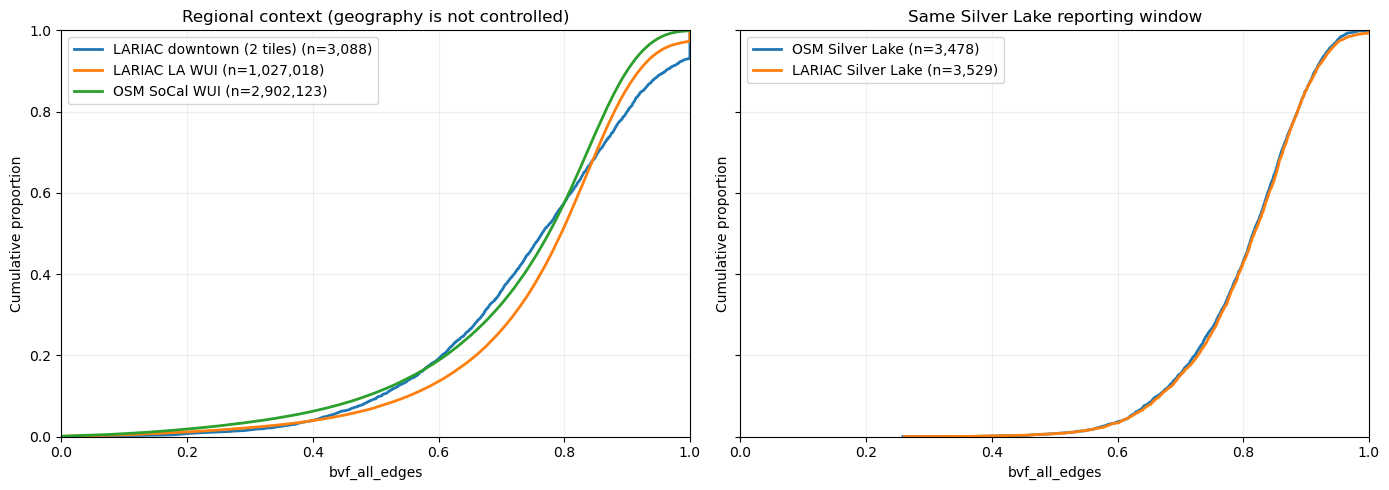

In [6]:
# BVF ECDF comparison: regional context and same-place source comparison.
from pathlib import Path
import duckdb
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyogrio
import shapely
from IPython.display import display
from scipy.spatial import cKDTree
from shapely.geometry import Point

PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
RESULTS = PROJECT / 'results'
OSM_PREPARED = PROJECT / 'data' / 'processed' / 'socal_wui_osm_2d'
LARIAC_PATH = Path('/Users/adamswietek/Documents/PostDoc/data/raw_la/laraic_files/LARIAC6_Buildings_2020.gdb')
LARIAC_LAYER = 'LARIAC6_BUILDINGS_2020'

metric_paths = {
    'LARIAC downtown (2 tiles)': RESULTS / 'bvf_two_tile_demo_bvh' / 'building_metrics.parquet',
    'LARIAC LA WUI': RESULTS / 'lariac6_wui_1mi_bvf_2d_bvh' / 'building_metrics.parquet',
    'OSM SoCal WUI': RESULTS / 'socal_wui_osm_2d' / 'full_socal' / 'building_metrics.parquet',
}
regional = {
    name: pd.read_parquet(path, columns=['bvf_all_edges'])['bvf_all_edges'].dropna().to_numpy()
    for name, path in metric_paths.items()
}

# Use the same reporting-safe footprint for both geometry sources.
COMPARISON_AREAS = {
    'Silver Lake': (-118.2702, 34.0869),
    'Pasadena foothills': (-118.1445, 34.1900),
}
COMPARISON_AREA = 'Silver Lake'
COMPARISON_RADIUS_M = 750.0
center = gpd.GeoSeries(
    [Point(COMPARISON_AREAS[COMPARISON_AREA])], crs=4326,
).to_crs(3310).iloc[0]
analysis_geometry = gpd.read_file(
    OSM_PREPARED / 'socal_wui_analysis_mask.gpkg', layer='mask',
).geometry.union_all()
reporting_geometry = shapely.buffer(analysis_geometry, -152.4)
comparison_mask = shapely.intersection(center.buffer(COMPARISON_RADIUS_M), reporting_geometry)

osm_footprints = pyogrio.read_dataframe(
    OSM_PREPARED / 'socal_wui_osm_buildings.fgb',
    columns=['building_id'], mask=comparison_mask,
)
osm_points = shapely.point_on_surface(osm_footprints.geometry.to_numpy())
osm_footprints = osm_footprints[shapely.within(osm_points, comparison_mask)].copy()

lariac_info = pyogrio.read_info(LARIAC_PATH, layer=LARIAC_LAYER)
lariac_mask = gpd.GeoSeries([comparison_mask], crs=3310).to_crs(lariac_info['crs']).iloc[0]
lariac_footprints = pyogrio.read_dataframe(
    LARIAC_PATH, layer=LARIAC_LAYER, mask=lariac_mask,
    columns=['BLD_ID'], fid_as_index=True,
).to_crs(3310)
lariac_footprints['building_id'] = lariac_footprints.index.astype('int64')
lariac_points = shapely.point_on_surface(lariac_footprints.geometry.to_numpy())
lariac_footprints = lariac_footprints[shapely.within(lariac_points, comparison_mask)].copy()

def _local_metrics(ids, path):
    con = duckdb.connect()
    con.register('local_ids', ids[['building_id']].drop_duplicates())
    sql_path = str(path).replace("'", "''")
    result = con.execute(f"""
        SELECT m.* FROM read_parquet('{sql_path}') m
        SEMI JOIN local_ids i USING (building_id)
    """).df()
    con.close()
    return result

local = {
    f'OSM {COMPARISON_AREA}': _local_metrics(
        osm_footprints, metric_paths['OSM SoCal WUI'],
    ),
    f'LARIAC {COMPARISON_AREA}': _local_metrics(
        lariac_footprints, metric_paths['LARIAC LA WUI'],
    ),
}

def _plot_ecdf(ax, values, label):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    probabilities = np.linspace(0, 1, 2001)
    ax.plot(np.quantile(values, probabilities), probabilities, lw=2, label=f'{label} (n={len(values):,})')

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)
for name, values in regional.items():
    _plot_ecdf(axes[0], values, name)
for name, frame in local.items():
    _plot_ecdf(axes[1], frame['bvf_all_edges'], name)
for ax in axes:
    ax.set(xlabel='bvf_all_edges', ylabel='Cumulative proportion', xlim=(0, 1), ylim=(0, 1))
    ax.grid(alpha=0.2)
    ax.legend()
axes[0].set_title('Regional context (geography is not controlled)')
axes[1].set_title(f'Same {COMPARISON_AREA} reporting window')
plt.tight_layout()

summary_rows = []
for name, values in {**regional, **{key: value['bvf_all_edges'].to_numpy() for key, value in local.items()}}.items():
    values = np.asarray(values, dtype=float)
    summary_rows.append({
        'sample': name, 'n': len(values), 'mean': np.nanmean(values),
        'q25': np.nanquantile(values, .25), 'median': np.nanmedian(values),
        'q75': np.nanquantile(values, .75),
    })
comparison_summary = pd.DataFrame(summary_rows).set_index('sample')
display(comparison_summary.round(4))

def _median_nearest_distance(frame):
    points = shapely.point_on_surface(frame.geometry.to_numpy())
    xy = np.column_stack([shapely.get_x(points), shapely.get_y(points)])
    return np.median(cKDTree(xy).query(xy, k=2)[0][:, 1])

coverage_summary = pd.DataFrame({
    'building_count': [len(osm_footprints), len(lariac_footprints)],
    'footprint_area_ha': [
        shapely.area(osm_footprints.geometry.to_numpy()).sum()/10_000,
        shapely.area(lariac_footprints.geometry.to_numpy()).sum()/10_000,
    ],
    'facade_length_km': [
        shapely.length(osm_footprints.geometry.to_numpy()).sum()/1_000,
        shapely.length(lariac_footprints.geometry.to_numpy()).sum()/1_000,
    ],
    'median_nearest_building_m': [
        _median_nearest_distance(osm_footprints),
        _median_nearest_distance(lariac_footprints),
    ],
}, index=[f'OSM {COMPARISON_AREA}', f'LARIAC {COMPARISON_AREA}'])
display(coverage_summary.round(2))